In [1]:
import os.path as op
import pickle
import hnn_core
from hnn_core import human_ET_model, simulate_dipole, MPIBackend
hnn_core_root = op.dirname(hnn_core.__file__)
from hnn_core.hnn_io import read_network_configuration
import matplotlib.pyplot as plt

In [ ]:
net

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/k

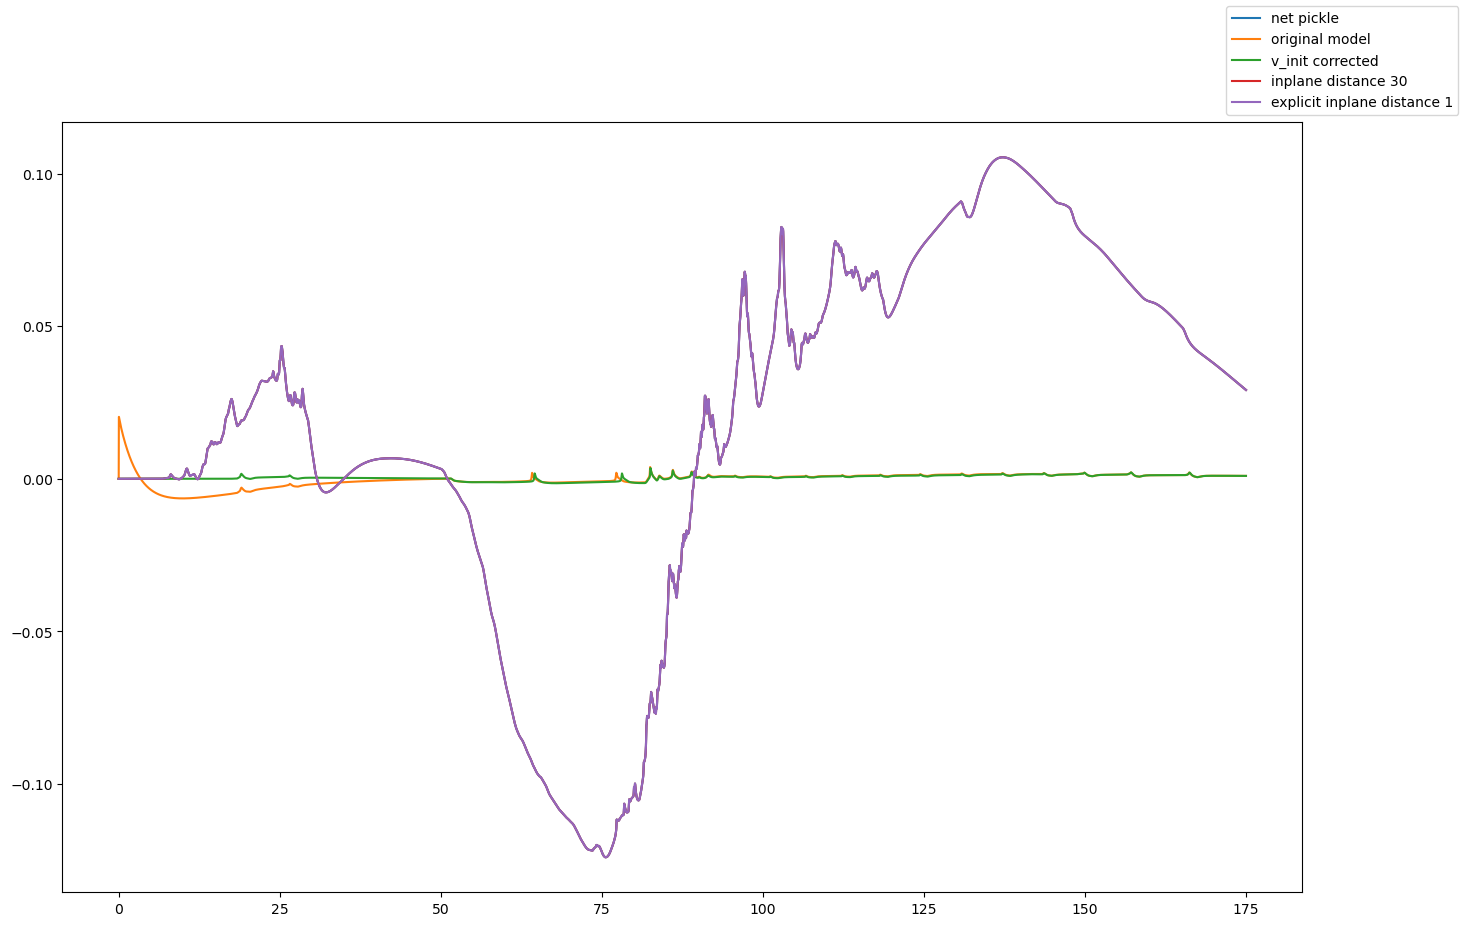

In [2]:
params_fname = op.join(hnn_core_root, 'param','default_human_ET_hierarchical.json')
net = read_network_configuration(params_fname)


with open('net_handtuned.pkl', 'rb') as file:
        net_hand = pickle.load(file)

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    pickle_dpl = simulate_dipole(net_hand, tstop=175, n_trials=1, bsl_cor='calcium')[0]
    read_config_dpl = simulate_dipole(net, tstop=175, n_trials=1, bsl_cor='calcium')[0]

fig, ax = plt.subplots(figsize=(16, 10))


ax.plot(pickle_dpl.times, pickle_dpl.data['agg'], label='net pickle')
ax.plot(read_config_dpl.times, read_config_dpl.data['agg'], label='original model')

# cell types initialization is different
net = read_network_configuration(params_fname)
net.cell_types = net_hand.cell_types

with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
    dpl_celltypes = simulate_dipole(net, tstop=175, n_trials=1, bsl_cor='calcium')[0]
ax.plot(dpl_celltypes.times, dpl_celltypes.data['agg'], label='v_init corrected')

net = read_network_configuration(params_fname)
net.cell_types = net_hand.cell_types
net.set_cell_positions(inplane_distance=30.)
with MPIBackend(n_procs=10, mpi_cmd='mpiexec'):
     dpl_inplane_distance = simulate_dipole(net, tstop=175, n_trials=1, bsl_cor='calcium')[0]
ax.plot(dpl_inplane_distance.times, dpl_inplane_distance.data['agg'], label='inplane distance 30')

net = read_network_configuration(params_fname)
net.cell_types = net_hand.cell_types
net.set_cell_positions(inplane_distance=1.)
dpl_explicit = simulate_dipole(net, tstop=175, n_trials=1, bsl_cor='calcium')[0]
ax.plot(dpl_explicit.times, dpl_explicit.data['agg'], label='explicit inplane distance 1')

fig.legend()